
停止接收，保留最后一帧图像


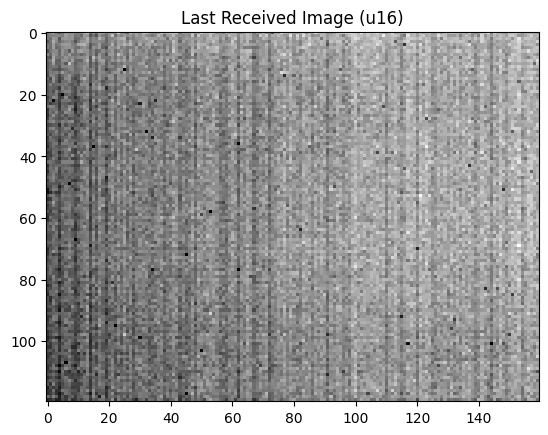

In [41]:
import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime

class ImagePacketDecoder:
    """解析固定大小图像包，包格式: FF FF + 大端 u16"""
    def __init__(self, width, height):
        self.width = width
        self.height = height
        self.packet_size = 2 + width * height * 2  # 包头 + u16 像素数据

    def feed_buffer(self, buf):
        """解析整个包"""
        if len(buf) != self.packet_size:
            return None
        if buf[0] != 0xFF or buf[1] != 0xFF:
            return None
        data_bytes = buf[2:]  # 去掉包头
        # img = np.frombuffer(data_bytes, dtype=">u2").reshape((self.height, self.width))
        buf = np.frombuffer(data_bytes, dtype=np.uint8)
        raw16 = (buf[0::2].astype(np.uint16) << 8) | \
                buf[1::2].astype(np.uint16)

        # Gray -> Binary (vectorized)
        bin16 = raw16.copy()
        bin16 ^= bin16 >> 1
        bin16 ^= bin16 >> 2
        bin16 ^= bin16 >> 4
        bin16 ^= bin16 >> 8

        img = bin16.reshape((self.height, self.width))
        return img, data_bytes


def run_uart_save_npy(port="COM8", baud=115200, width=160, height=120):
    # 启动时创建文件夹
    folder_name = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    os.makedirs(folder_name, exist_ok=True)
    npy_file_path = os.path.join(folder_name, "frames.npy")
    print(f"数据将保存到: {npy_file_path}")

    decoder = ImagePacketDecoder(width, height)
    buf = bytearray()
    header_found = False
    all_frames = []

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("等待图像帧... 按 Ctrl-C 停止")
            while True:
                raw = ser.read(1024)  # 批量读取
                if not raw:
                    continue

                buf.extend(raw)

                while True:
                    # 查找包头
                    if not header_found:
                        idx = buf.find(b'\xFF\xFF')
                        if idx == -1:
                            # 没找到完整包头，保留最后一个字节防止断包
                            if len(buf) > 1:
                                buf = buf[-1:]
                            break
                        else:
                            buf = buf[idx:]
                            header_found = True

                    # 包完整则解析
                    if len(buf) >= decoder.packet_size:
                        packet = buf[:decoder.packet_size]
                        buf = buf[decoder.packet_size:]
                        header_found = False

                        result = decoder.feed_buffer(packet)
                        if result is not None:
                            img, data_bytes = result
                            all_frames.append(img)
                            # 保存到 npy 文件，每帧追加
                            np.save(npy_file_path, np.array(all_frames))
                            print(f"写入 {len(data_bytes)} bytes 到 {npy_file_path}")

                            # 显示图像
                            clear_output(wait=True)
                            plt.imshow(img, cmap="gray")
                            plt.title(f"Received Image (u16) - {len(all_frames)} frames")
                            plt.show()
                    else:
                        break
    except KeyboardInterrupt:
        print("\n停止接收，保留最后一帧图像")
        if all_frames:
            plt.figure()
            plt.imshow(all_frames[-1], cmap="gray")
            plt.title("Last Received Image (u16)")
            plt.show()


run_uart_save_npy("COM31", 5000000, 160, 120)

In [ ]:
import numpy as np

buf = bytes([
    0xFF, 0xFF,
    0x09, 0x93,   # 2451
    0x12, 0x34,   # 4660
])

img = np.frombuffer(buf[2:], dtype=">u2")
print(img)


[2451 4660]


In [ ]:
arr_u8 = np.frombuffer(buf, dtype=np.uint8)
raw16 = (arr_u8[0::2].astype(np.uint16) << 8) | arr_u8[1::2]
print(raw16)

[2451 4660    1]
